# Tutorial: GION convergence maps

This notebook shows how to read a GION weak-lensing convergence ($\kappa$) map and visualise it.

**Before running:** download the map used here (`zs_idx = 124`) with [`download_kappa.sh`](download_kappa.sh):

```sh
sh download_kappa.sh 124
```

The map is saved as `lensing_maps/GION_r000_kappa.124.fits`. Each map is about 6.4 GB, and loading it needs a similar amount of memory.

## Setup

The maps are full-sky HEALPix maps with $N_\mathrm{side} = 8192$, which we read with `healpy`.

In [1]:
import numpy as np
import healpy as hp
import matplotlib.pyplot as plt

## Source redshifts

Each map corresponds to a single source plane, labelled by the index `zs_idx`. Source planes are spaced every $25 \, h^{-1} \, \mathrm{Mpc}$ in comoving distance. The full suite has 216 planes (`zs_idx` = 0–215) up to $z_s \simeq 5.1$, and the QDR provides `zs_idx` = 95–163 ($0.50 \lesssim z_s \lesssim 1.50$, shaded below). Note that the source redshift decreases with increasing index.

The source redshift of each index is listed in [`zs_kappa.txt`](zs_kappa.txt).

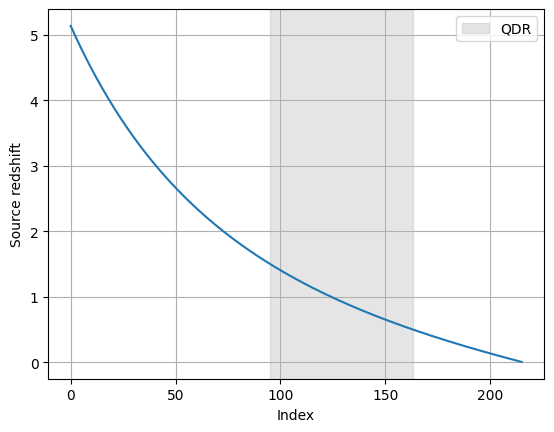

In [2]:
d = np.loadtxt('zs_kappa.txt')

plt.plot(d[:, 0], d[:, 1])
plt.axvspan(95, 163, color='gray', alpha=0.2, label='QDR')
plt.xlabel('Index')
plt.ylabel('Source redshift')
plt.legend()
plt.grid()
plt.show()

## Loading a map

Let's load the map with `zs_idx = 124`, whose source redshift is $z_s \simeq 1.005$.

In [3]:
zs_idx = 124
zs = d[d[:, 0] == zs_idx, 1][0]
print(f"Source redshift: z_s = {zs:.4f}")

m = hp.read_map(f"lensing_maps/GION_r000_kappa.{zs_idx}.fits")
nside = hp.get_nside(m)
npix = hp.nside2npix(nside)
print("Nside:", nside)
print("Npix:", npix)

Source redshift: z_s = 1.0052
Nside: 8192
Npix: 805306368


## Visualising the map

We show the full-sky map in the Mollweide projection. The colour range is limited to $-0.05 < \kappa < 0.1$ to bring out the large-scale structure.

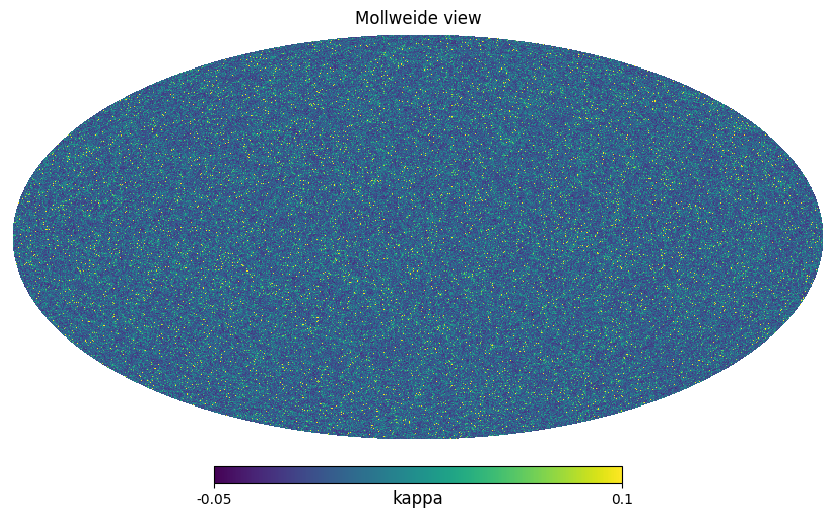

In [4]:
hp.mollview(m, unit="kappa", min=-0.05, max=0.1, cmap='viridis')
plt.show()

At this resolution, the full-sky view cannot show small-scale structure. Let's zoom into a $5^\circ \times 5^\circ$ patch with the gnomonic projection (750 pixels of 0.4 arcmin, comparable to the HEALPix pixel size of about 0.43 arcmin).

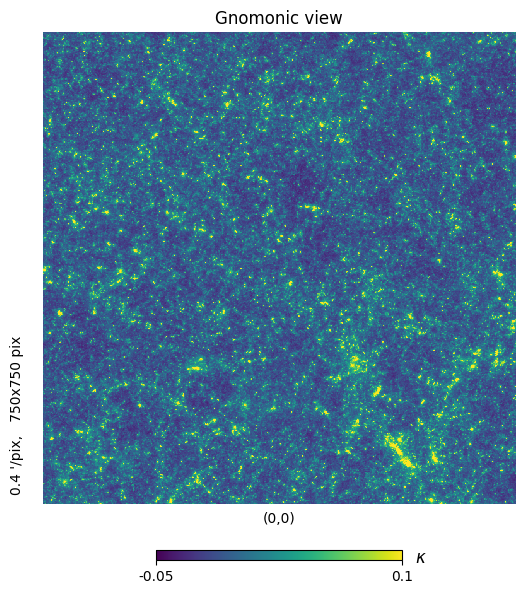

In [6]:
hp.gnomview(m, rot=(0.0, 0.0), xsize=750, reso=0.4, unit=r"$\kappa$", min=-0.05, max=0.1, cmap='viridis')
plt.show()